## 6-7_Finding_the_closest_object_in_the_feature_space

In [1]:
## 1. Generate sample points for nearest-neighbor analysis.

import numpy as np

from sklearn.metrics import pairwise
from sklearn.datasets import make_blobs
points, labels = make_blobs()

In [2]:
## 2. Calculate pairwise distances between all points.

distances = pairwise.pairwise_distances(points)
np.diag(distances) [:5]

array([0., 0., 0., 0., 0.])

In [4]:
## 3. Inspect distances from the first point to other points.

distances[0][:5]

array([ 0.        ,  2.73112375,  2.44324119,  2.09999785, 11.88773824])

In [5]:
## 4. Rank the points by distance from the first point.

ranks = np.argsort(distances[0])
ranks[:5]

array([ 0, 66, 23, 12, 39])

In [6]:
## 5. Retrieve the coordinates of the closest points.

points[ranks][:5]

array([[-2.14146754,  1.2557139 ],
       [-2.47923313,  1.09224985],
       [-2.48189603,  2.11178399],
       [-3.44904101,  1.04525837],
       [-2.55796274,  2.62065732]])

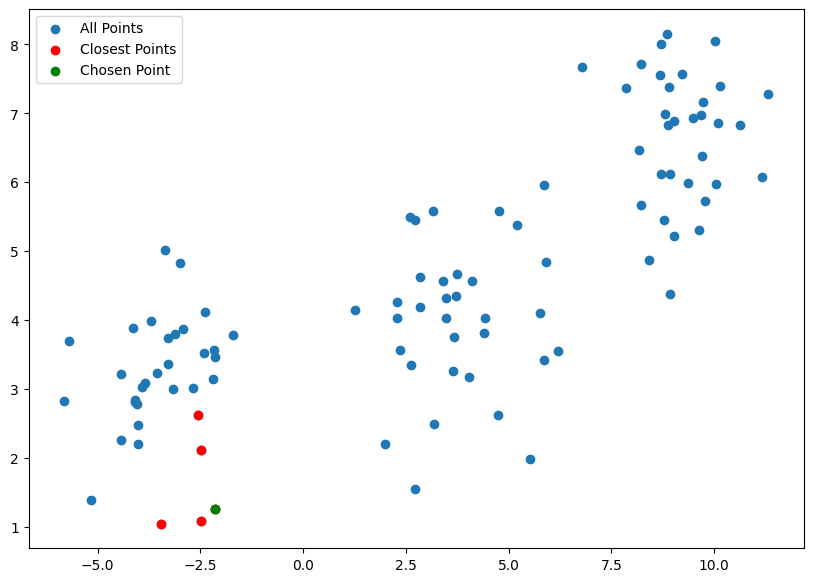

In [7]:
## 6. Visualize the closest points in the feature space.

import matplotlib.pyplot as plt
%matplotlib inline

sp_points = points[ranks][:5]

plt.figure(figsize=(10,7))
plt.scatter(points[:,0], points[:,1], label = 'All Points')
plt.scatter(sp_points[:,0],sp_points[:,1],color='red', label='Closest Points')
plt.scatter(points[0,0],points[0,1],color='green', label = 'Chosen Point')

plt.legend()

In [8]:
## 7. Implement and calculate Euclidean distance.

def euclid_distances(x, y):
     return np.power(np.power(x - y, 2).sum(), .5)

euclid_distances(points[0], points[1])

np.float64(2.7311237549936833)

In [9]:
## 8. Calculate Manhattan distance using the cityblock metric.

pairwise.pairwise_distances([[0, 0], [5, 5]], metric='cityblock')[0]

array([ 0., 10.])

In [10]:
## 9. Generate binary data for Hamming distance calculation.

X = np.random.binomial(1, .5, size=(2, 4)).astype(bool)
X

array([[ True, False,  True,  True],
       [ True,  True, False, False]])

In [11]:
## 10. Calculate pairwise Hamming distances.

pairwise.pairwise_distances(X, metric='hamming')

array([[0.  , 0.75],
       [0.75, 0.  ]])